In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd
from spacepy import pycdf
import numpy as np
from scipy.signal import butter, filtfilt
from scipy.linalg import eig
import matplotlib.pyplot as plt

# Load the CDF file
cdf_path = '/home/draksha/pydata/mms1/fgm/srvy/l2/2015/10/mms1_fgm_srvy_l2_20151028_v4.18.0.cdf'
cdf = pycdf.CDF(cdf_path)
cdf

<CDF:
Epoch: CDF_TIME_TT2000 [1051008]
Epoch_state: CDF_TIME_TT2000 [2883]
label_b_bcs: CDF_CHAR*10 [4] NRV
label_b_dmpa: CDF_CHAR*10 [4] NRV
label_b_gse: CDF_CHAR*10 [4] NRV
label_b_gsm: CDF_CHAR*11 [4] NRV
label_r_gse: CDF_CHAR*10 [4] NRV
label_r_gsm: CDF_CHAR*10 [4] NRV
mms1_fgm_b_bcs_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_b_dmpa_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_b_gse_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_b_gsm_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_bdeltahalf_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_etemp_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_flag_srvy_l2: CDF_UINT4 [1051008]
mms1_fgm_hirange_srvy_l2: CDF_UINT1 [1051008]
mms1_fgm_mode_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_r_gse_srvy_l2: CDF_REAL4 [2883, 4]
mms1_fgm_r_gsm_srvy_l2: CDF_REAL4 [2883, 4]
mms1_fgm_rdeltahalf_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_stemp_srvy_l2: CDF_FLOAT [1051008]
represent_vec_tot: CDF_CHAR*1 [4] NRV
>

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize

# Extract the magnetic field data and timestamps
datetime = pd.to_datetime(cdf['Epoch'][:])
B_x = cdf['mms1_fgm_b_gse_srvy_l2'][:, 0]
B_y = cdf['mms1_fgm_b_gse_srvy_l2'][:, 1]
B_z = cdf['mms1_fgm_b_gse_srvy_l2'][:, 2]

# Combine the data into a DataFrame and remove NaN values
data = pd.DataFrame({'datetime': datetime, 'B_x': B_x, 'B_y': B_y, 'B_z': B_z}).set_index('datetime')
data.dropna(inplace=True)

# Define the bandpass filter function
def bandpass_filter(data, lowcut, highcut, sampling_freq, order=4):
    nyquist = 0.5 * sampling_freq
    low, high = lowcut / nyquist, highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data, padtype='odd')  # Edge handling with 'odd' padding

# Calculate the sampling frequency
time_diff = np.diff(data.index.values.astype('datetime64[ns]').astype(float)) / 1e9  # Convert to seconds
sampling_freq = 1 / np.mean(time_diff)  # Hz

# Define the bandpass filter frequency range
lowcut, highcut = 0.05, 5  # Hz

# Apply the bandpass filter to each magnetic field component
data['B_x_f'] = bandpass_filter(data['B_x'].values, lowcut, highcut, sampling_freq)
data['B_y_f'] = bandpass_filter(data['B_y'].values, lowcut, highcut, sampling_freq)
data['B_z_f'] = bandpass_filter(data['B_z'].values, lowcut, highcut, sampling_freq)

# Select the filtered data within the specified time range
start_time, end_time = pd.Timestamp('2015-10-28 16:45:03.260000'), pd.Timestamp('2015-10-28 16:45:06.385100')
filtered_data = data[(data.index >= start_time) & (data.index <= end_time)]



In [4]:

# Calculate mean values for the filtered components
m1, m2, m3 = filtered_data[['B_x_f', 'B_y_f', 'B_z_f']].mean()

# Manually calculate the covariance matrix components
M11 = np.mean((filtered_data['B_x_f'] - m1) * (filtered_data['B_x_f'] - m1))
M12 = np.mean((filtered_data['B_x_f'] - m1) * (filtered_data['B_y_f'] - m2))
M13 = np.mean((filtered_data['B_x_f'] - m1) * (filtered_data['B_z_f'] - m3))

M21 = M12
M22 = np.mean((filtered_data['B_y_f'] - m2) * (filtered_data['B_y_f'] - m2))
M23 = np.mean((filtered_data['B_y_f'] - m2) * (filtered_data['B_z_f'] - m3))

M31 = M13
M32 = M23
M33 = np.mean((filtered_data['B_z_f'] - m3) * (filtered_data['B_z_f'] - m3))

# Construct the covariance matrix manually
M = np.array([[M11, M12, M13],
              [M21, M22, M23],
              [M31, M32, M33]])


# # eig_vals,eig_vecs = np.linalg.eigh(M)



# Compute eigenvectors using SVD
U, S, _ = np.linalg.svd(M)  
eig_vals, eig_vecs = S, U

idx = np.argsort(eig_vals)[::-1]
eig_vals = eig_vals[idx]
eig_vecs  = eig_vecs[:,idx]





if eig_vecs[0, 1] < 0:
    eig_vecs[:, 1] *= -1



# Ensure a right-handed coordinate system
X = np.cross(eig_vecs[:, 0], eig_vecs[:, 1])
Y = eig_vecs[:,2]
if np.dot(X, Y) < 0:
    eig_vecs[:, 1] *= -1
    eig_vecs[:, 2] *= -1






In [5]:
eig_vecs

array([[-0.92560574,  0.0673385 ,  0.37245071],
       [-0.12119596, -0.98496428, -0.12311337],
       [ 0.35856038, -0.15909396,  0.91984975]])

In [6]:
X,Y

(array([ 0.37245071, -0.12311337,  0.91984975]),
 array([ 0.37245071, -0.12311337,  0.91984975]))

In [7]:
# (Optional) You can add further sign checks if needed, but the first and third columns already match.
print("Eigenvalues:\n", eig_vals)
print("Eigenvectors:\n", eig_vecs)


# Transform the magnetic field data into the MVA coordinate system
mva_matrix = np.dot(filtered_data[['B_x_f', 'B_y_f', 'B_z_f']], eig_vecs)
filtered_data[['B_L', 'B_M', 'B_N']] = mva_matrix

Eigenvalues:
 [2.45379550e-01 1.23129259e-02 7.41225016e-05]
Eigenvectors:
 [[-0.92560574  0.0673385   0.37245071]
 [-0.12119596 -0.98496428 -0.12311337]
 [ 0.35856038 -0.15909396  0.91984975]]


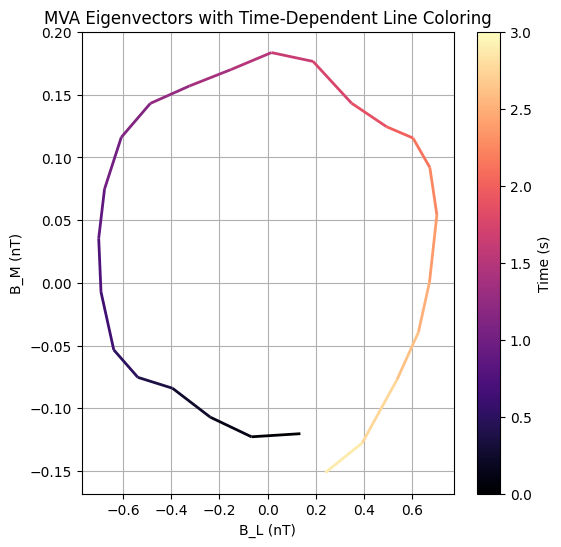

In [8]:
# Plot the transformed magnetic field data
time_numeric = (filtered_data.index - filtered_data.index[0]).total_seconds()

# Prepare the data for the line segments
x, y = filtered_data['B_L'].values, filtered_data['B_M'].values
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

# Create the colormap and normalize time
norm = Normalize(vmin=time_numeric.min(), vmax=time_numeric.max())
lc = LineCollection(segments, cmap='magma', norm=norm)
lc.set_array(time_numeric)  # Use numeric time for color mapping
lc.set_linewidth(2)

# Plot the line with color gradation
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_collection(lc)
ax.autoscale()
ax.set_xlabel('B_L (nT)')
ax.set_ylabel('B_M (nT)')
ax.set_title('MVA Eigenvectors with Time-Dependent Line Coloring')
plt.colorbar(lc, ax=ax, label='Time (s)')
plt.grid()
plt.show()

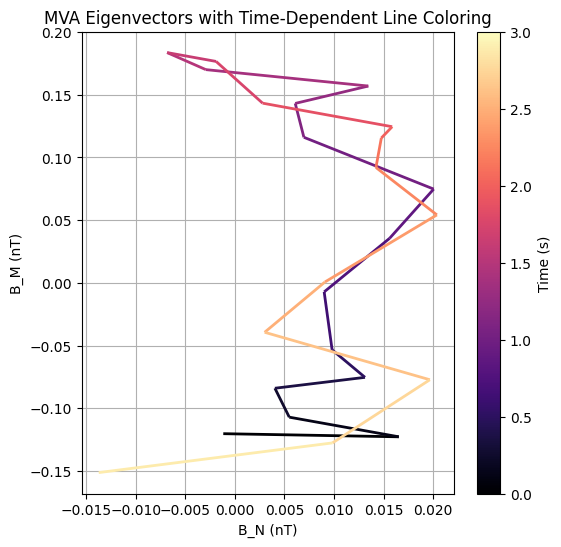

In [9]:
# Prepare the data for the line segments
x, y = filtered_data['B_N'].values, filtered_data['B_M'].values
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

# Create the colormap and normalize time
norm = Normalize(vmin=time_numeric.min(), vmax=time_numeric.max())
lc = LineCollection(segments, cmap='magma', norm=norm)
lc.set_array(time_numeric)  # Use numeric time for color mapping
lc.set_linewidth(2)

# Plot the line with color gradation
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_collection(lc)
ax.autoscale()
ax.set_xlabel('B_N (nT)')
ax.set_ylabel('B_M (nT)')
ax.set_title('MVA Eigenvectors with Time-Dependent Line Coloring')
plt.colorbar(lc, ax=ax, label='Time (s)')
plt.grid()
plt.show()

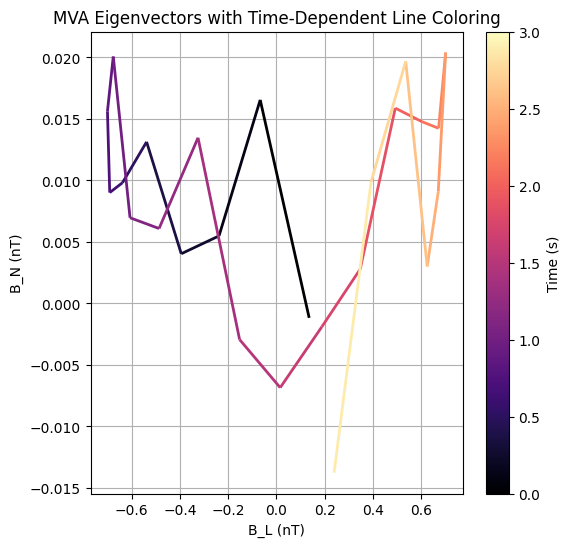

In [10]:
# Prepare the data for the line segments
x, y = filtered_data['B_L'].values, filtered_data['B_N'].values
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

# Create the colormap and normalize time
norm = Normalize(vmin=time_numeric.min(), vmax=time_numeric.max())
lc = LineCollection(segments, cmap='magma', norm=norm)
lc.set_array(time_numeric)  # Use numeric time fr color mapping
lc.set_linewidth(2)

# Plot the line with color gradation
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_collection(lc)
ax.autoscale()
ax.set_xlabel('B_L (nT)')
ax.set_ylabel('B_N (nT)')
ax.set_title('MVA Eigenvectors with Time-Dependent Line Coloring')
plt.colorbar(lc, ax=ax, label='Time (s)')
plt.grid()
plt.show()

In [11]:
import pandas as pd
from spacepy import pycdf
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt


# Extract the magnetic field data and timestamps
datetime = pd.to_datetime(cdf['Epoch'][:])
b_x = cdf['mms1_fgm_b_gse_srvy_l2'][:, 0]
b_y = cdf['mms1_fgm_b_gse_srvy_l2'][:, 1]
b_z = cdf['mms1_fgm_b_gse_srvy_l2'][:, 2]
b_t = cdf['mms1_fgm_b_gse_srvy_l2'][:, 3]

# Create DataFrame
df = pd.DataFrame({'datetime': datetime, 'b_x': b_x, 'b_y': b_y, 'b_z': b_z, 'b_t': b_t}).set_index('datetime')

# Compute Sampling Frequency
time_diff = np.diff(df.index.astype('int64')) / 1e9  # Convert nanoseconds to seconds
fs = 1 / np.mean(time_diff)  # Hz

# Define Butterworth Low-Pass Filter
def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs  # Nyquist Frequency
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    return filtfilt(b, a, data)  # Use filtfilt for zero-phase filtering

# Apply Low-Pass Filter
cutoff_freq = 0.05  # Hz
df['B0_x'] = butter_lowpass_filter(df['b_x'], cutoff_freq, fs)
df['B0_y'] = butter_lowpass_filter(df['b_y'], cutoff_freq, fs)
df['B0_z'] = butter_lowpass_filter(df['b_z'], cutoff_freq, fs)
df['B0_t'] = butter_lowpass_filter(df['b_t'], cutoff_freq, fs)


# Select the filtered data within the specified time range
start_time = pd.Timestamp('2015-10-28 16:45:03.255000')
end_time = pd.Timestamp('2015-10-28 16:45:06.385000')
# filtered_data = data.loc[start_time:end_time]
# # Define time range
# start_time = pd.Timestamp('2015-10-28 13:00:00')
# end_time = pd.Timestamp('2015-10-28 17:30:00')

# # Filter dataframe for plotting
df_filtered = df.loc[start_time:end_time]



In [12]:
Bx0,By0,Bz0 = np.mean(df_filtered['B0_x']),np.mean(df_filtered['B0_y']),np.mean(df_filtered['B0_z'])
Bx0,By0, Bz0

(np.float64(14.745973326262948),
 np.float64(13.413550681488493),
 np.float64(44.00878574523771))

In [13]:
B0 = np.array([Bx0,By0,Bz0])
K = eig_vecs[:,2]

In [14]:
import numpy as np

# Compute the angle (convert to degrees)
theta = np.degrees(np.arccos(np.dot(K,B0) / (np.linalg.norm(K) * np.linalg.norm(B0))))

print(f"Angle θ between K and B0: {theta:.2f} degrees")


Angle θ between K and B0: 23.45 degrees
